# Task 5 — Initial Descriptive Analysis

**Research question:** How accurately can classical regression models estimate engine Remaining Useful Life (RUL) from sensor data compared with a simple baseline?

Purpose: descriptive statistics, trends, hypotheses, grouping, and business implications. This is NOT a regression-model evaluation. Form hypotheses from training histories only; validation is reserved for descriptive replication, and test/quarantine data must not drive decisions. The retrospective RUL target is for analysis only, never a model input.

**Updated 11 November 2026 for the V6 milestone.** Original analysis by Denzel; execution/provenance and reporting completion assisted by Codex. Default input is the tracked Task 3-derived flight reconstruction. It supports these descriptive variables but does not restore within-flight variance or reprocess raw Kaggle data. The full Task 4 input is an explicit option. See the source manifest generated below.

No significance testing or causal “validation” is asserted for H1–H4. Validation results were already seen during integration review; the check is descriptive, not blinded confirmation.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
here=Path.cwd().resolve()
root=next((p for p in [here,*here.parents] if (p/'src/descriptive_analysis.py').exists()),None)
if root is None: raise FileNotFoundError('Open this notebook within the repository')
sys.path.insert(0,str(root))
from src.descriptive_analysis import load_flights,training_insights,insight_markdown
SOURCE='reconstructed'  # or 'full_task4' with the local prepared files present
all_flights,provenance=load_flights(root,SOURCE)
train=all_flights.loc[all_flights.split=='train'].copy()
validation=all_flights.loc[all_flights.split=='validation'].copy()
assert set(train.conservative_group).isdisjoint(validation.conservative_group)
figdir=root/'reports/figures/task5';outdir=root/'reports/results/task5'
figdir.mkdir(parents=True,exist_ok=True);outdir.mkdir(parents=True,exist_ok=True)
sensors=['T48_K_mean','Nc_rpm_mean','Wf_kg_s_mean']
conditions=['alt_m_mean','Mach_mean','TRA_pct_mean']
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
print('Input:',provenance['description'])
print('Training flights:',len(train),'source histories:',train.engine_id.nunique(),
      'conservative groups:',train.conservative_group.nunique())
(outdir/'analysis_provenance.json').write_text(json.dumps(provenance,indent=2)+'\n')
display(train[['dataset','engine_id','cycle','RUL']].head())

Input: Task 3 cycle aggregates; reconstructed means and causal history, not full Task 4 variances
Training flights: 574 source histories: 7 conservative groups: 6


,dataset,engine_id,cycle,RUL
0,DS01,DS01:1,1,99
1,DS01,DS01:1,2,98
2,DS01,DS01:1,3,97
3,DS01,DS01:1,4,96
4,DS01,DS01:1,5,95


## 1. Descriptive statistics and RUL distributions
Report engine-level and flight-level values separately: flights within one engine are dependent, not independent experimental subjects.

,count,mean,std,min,10%,25%,50%,75%,90%,max
RUL,574.0,41.834495,25.891210,0.000000,8.000000,20.000000,40.500000,61.000000,78.700000,99.000000
T48_K_mean,574.0,911.540901,10.342998,880.480526,899.624403,904.846730,911.262665,917.747523,924.098678,959.552641
Nc_rpm_mean,574.0,8239.921032,46.925133,8120.757790,8167.732332,8211.918620,8245.176570,8272.240993,8302.113620,8333.997921
Wf_kg_s_mean,574.0,1.155941,0.127818,0.899730,0.983831,1.047307,1.163105,1.271089,1.324967,1.376842
alt_m_mean,574.0,4739.440690,1784.465504,2245.261570,2459.441954,2993.065709,4749.742954,6396.416572,7107.861599,8060.018723
Mach_mean,574.0,0.538981,0.079745,0.364927,0.434716,0.473754,0.539273,0.612789,0.642646,0.679659
TRA_pct_mean,574.0,60.427287,7.851080,48.783404,49.575123,52.815260,60.020751,67.755079,70.890338,76.512145


,dataset,engine_id,flights,max_RUL,min_RUL
0,DS01,DS01:1,100,99,0
1,DS01,DS01:2,75,74,0
2,DS01,DS01:3,100,99,0
3,DS01,DS01:4,95,94,0
4,DS02,DS02:16,63,62,0
5,DS02,DS02:2,75,74,0
6,DS02,DS02:20,66,65,0


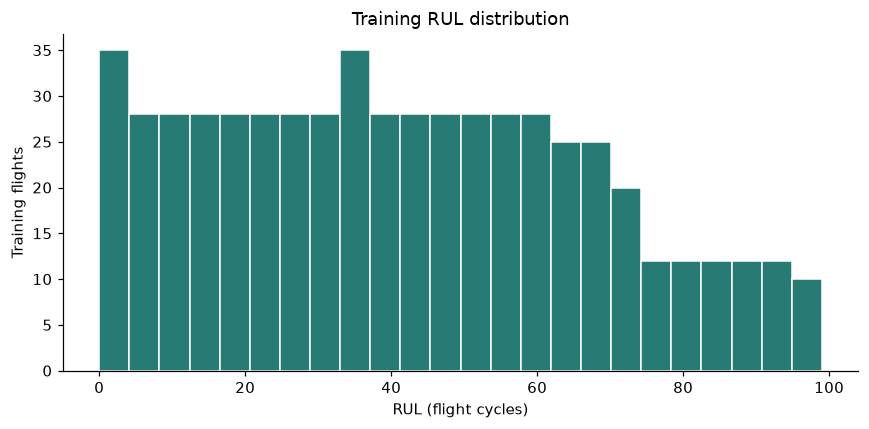

In [2]:
summary=train[["RUL",*sensors,*conditions]].describe(percentiles=[.1,.25,.5,.75,.9]).T
summary.to_csv(outdir/"train_descriptive_statistics.csv")
display(summary)
per_engine=train.groupby(["dataset","engine_id"],observed=True).agg(flights=("RUL","size"),max_RUL=("RUL","max"),min_RUL=("RUL","min")).reset_index()
per_engine.to_csv(outdir/"train_engine_counts.csv",index=False)
display(per_engine)
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(train.RUL,bins=24,color="#287b75",edgecolor="white")
ax.set(xlabel="RUL (flight cycles)",ylabel="Training flights",title="Training RUL distribution")
fig.tight_layout()
fig.savefig(figdir/"01_train_rul_histogram.svg",metadata={"Date":None})
fig.savefig(figdir/"01_train_rul_histogram.png",dpi=180)
plt.show()

## 2. Sensor trajectories by engine
Evaluate T48 temperature, core shaft speed Nc, and fuel flow Wf through the observed engine cycles. These signals are also affected by operating conditions; avoid causal claims.

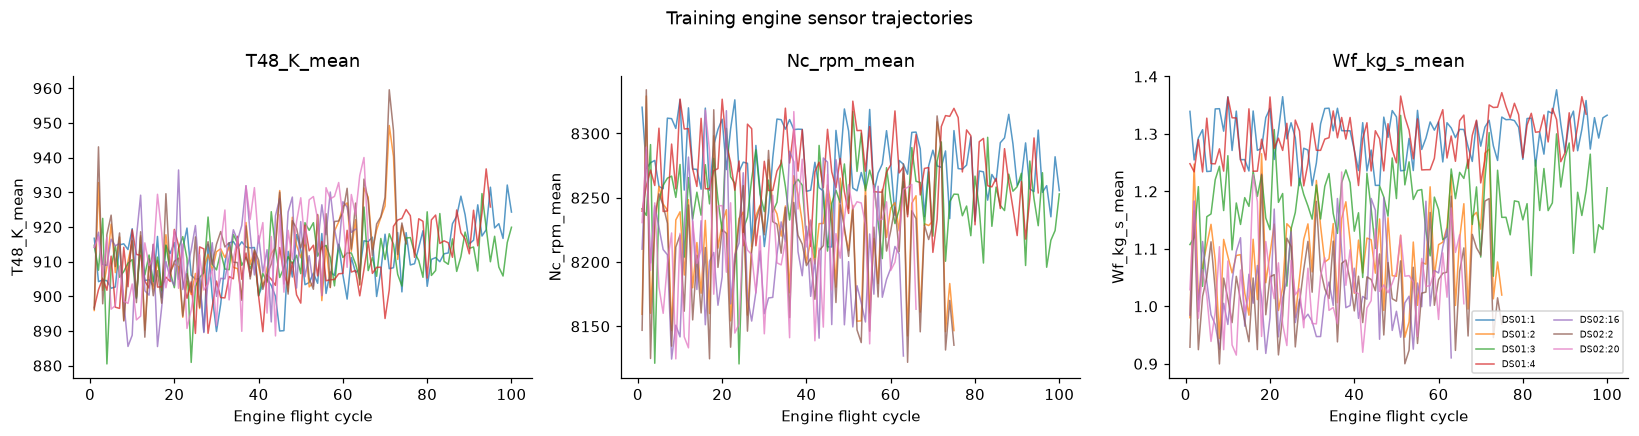

In [3]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,feature in zip(axes,sensors):
    for eid,g in train.groupby("engine_id"):
        g=g.sort_values("cycle")
        ax.plot(g.cycle,g[feature],alpha=.75,lw=1,label=eid)
    ax.set(xlabel="Engine flight cycle",ylabel=feature,title=feature)
axes[-1].legend(fontsize=6,ncol=2)
fig.suptitle("Training engine sensor trajectories")
fig.tight_layout()
fig.savefig(figdir/"02_sensor_trajectories.svg",bbox_inches="tight",metadata={"Date":None})
fig.savefig(figdir/"02_sensor_trajectories.png",bbox_inches="tight",dpi=180)
plt.show()

## 3. Sensor–RUL correlation and heterogeneity
H1: sensors vary with RUL. H4: relationships differ across engines/datasets. Pearson correlations summarize associations only; treat each engine history as a unit for comparison.

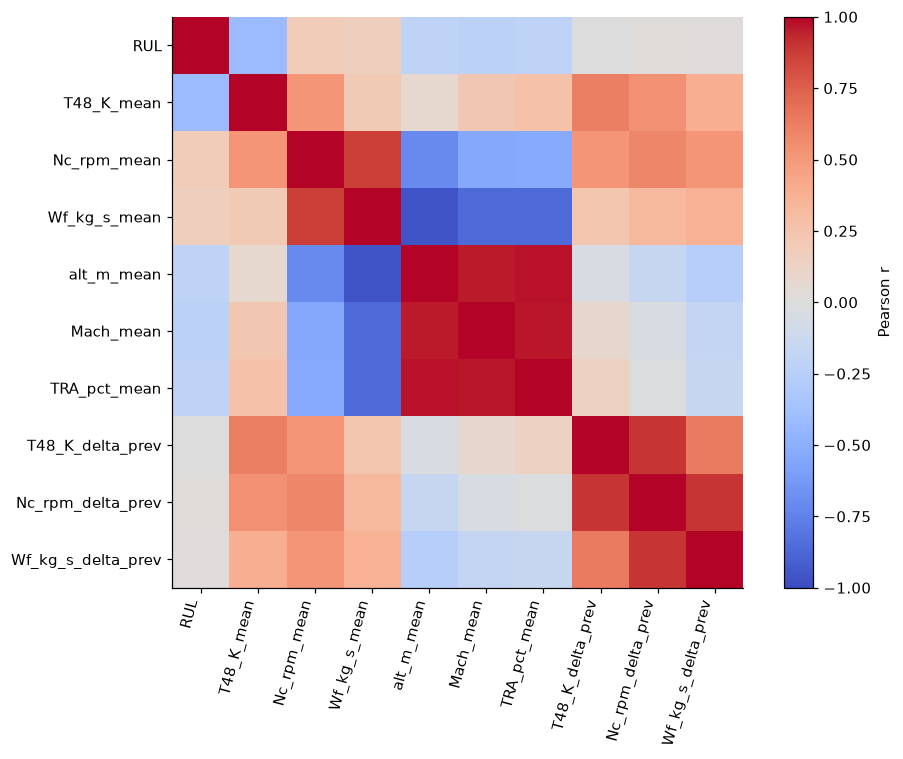

sensor,Nc_rpm_mean,T48_K_mean,Wf_kg_s_mean
engine_id,,,
DS01:1,0.199210,-0.419165,-0.158848
DS01:2,0.015174,-0.470592,-0.152072
DS01:3,0.014268,-0.299107,-0.085057
DS01:4,0.066873,-0.539628,-0.313343
DS02:16,0.111182,-0.355478,-0.073298
DS02:2,-0.005458,-0.417698,-0.150770
DS02:20,-0.153012,-0.516700,-0.134957


In [4]:
features=["RUL",*sensors,*conditions,"T48_K_delta_prev","Nc_rpm_delta_prev","Wf_kg_s_delta_prev"]
corr=train[features].corr(numeric_only=True)
corr.to_csv(outdir/"train_correlation_matrix.csv")
fig,ax=plt.subplots(figsize=(9,7))
im=ax.imshow(corr,vmin=-1,vmax=1,cmap="coolwarm")
ax.set_xticks(range(len(features)),features,rotation=75,ha="right")
ax.set_yticks(range(len(features)),features)
fig.colorbar(im,ax=ax,label="Pearson r")
fig.tight_layout()
fig.savefig(figdir/"03_train_correlation_heatmap.svg",bbox_inches="tight",metadata={"Date":None})
fig.savefig(figdir/"03_train_correlation_heatmap.png",bbox_inches="tight",dpi=180)
plt.show()
rows=[]
for eid,g in train.groupby("engine_id"):
    for sensor in sensors:
        rows.append({"engine_id":eid,"sensor":sensor,"r_with_RUL":g[["RUL",sensor]].corr().iloc[0,1]})
engine_corr=pd.DataFrame(rows)
engine_corr.to_csv(outdir/"train_per_engine_correlations.csv",index=False)
display(engine_corr.pivot(index="engine_id",columns="sensor",values="r_with_RUL"))

## 4. Life-stage grouping (retrospective only)
Segment historical flights into Late RUL 0–20, Middle 21–50, Early >50. These fixed illustrative boundaries use the target label and must never be used as predictive model inputs or deployment logic. Aggregate first within each engine, then compare engines rather than treating flights as independent.

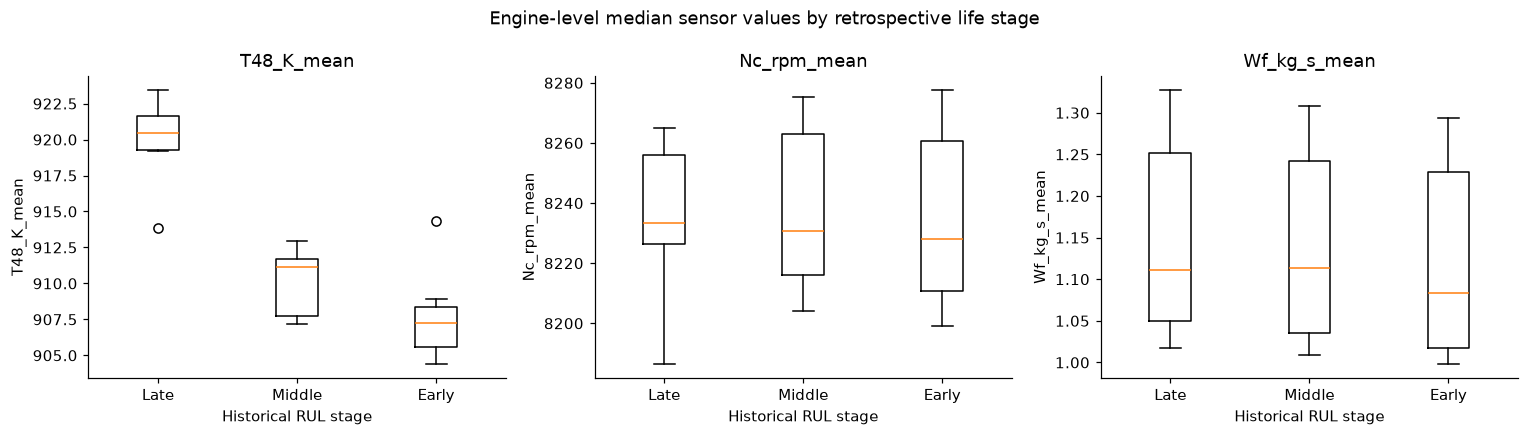

In [5]:
train["life_stage"]=pd.cut(train.RUL,[-1,20,50,np.inf],labels=["Late","Middle","Early"])
medians=train.groupby(["dataset","engine_id","life_stage"],observed=True)[sensors].median().reset_index()
medians.to_csv(outdir/"train_life_stage_engine_medians.csv",index=False)
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,sensor in zip(axes,sensors):
    vals=[medians.loc[medians.life_stage==s,sensor].dropna() for s in ["Late","Middle","Early"]]
    ax.boxplot(vals,tick_labels=["Late","Middle","Early"])
    ax.set(xlabel="Historical RUL stage",ylabel=sensor,title=sensor)
fig.suptitle("Engine-level median sensor values by retrospective life stage")
fig.tight_layout()
fig.savefig(figdir/"04_life_stage_sensor_boxplots.svg",bbox_inches="tight",metadata={"Date":None})
fig.savefig(figdir/"04_life_stage_sensor_boxplots.png",bbox_inches="tight",dpi=180)
plt.show()

## 5. Operating conditions and possible confounding
H3: altitude, Mach and throttle differ across life stages. Describe whether apparent sensor trends could reflect flight conditions, rather than degradation. These plots do not prove adjusted or causal effects.

These condition boxplots summarize flights, so engines with more flights receive greater weight. The sensor-stage boxplots above instead compare engine-level medians. Neither should be read as independent-subject inference.

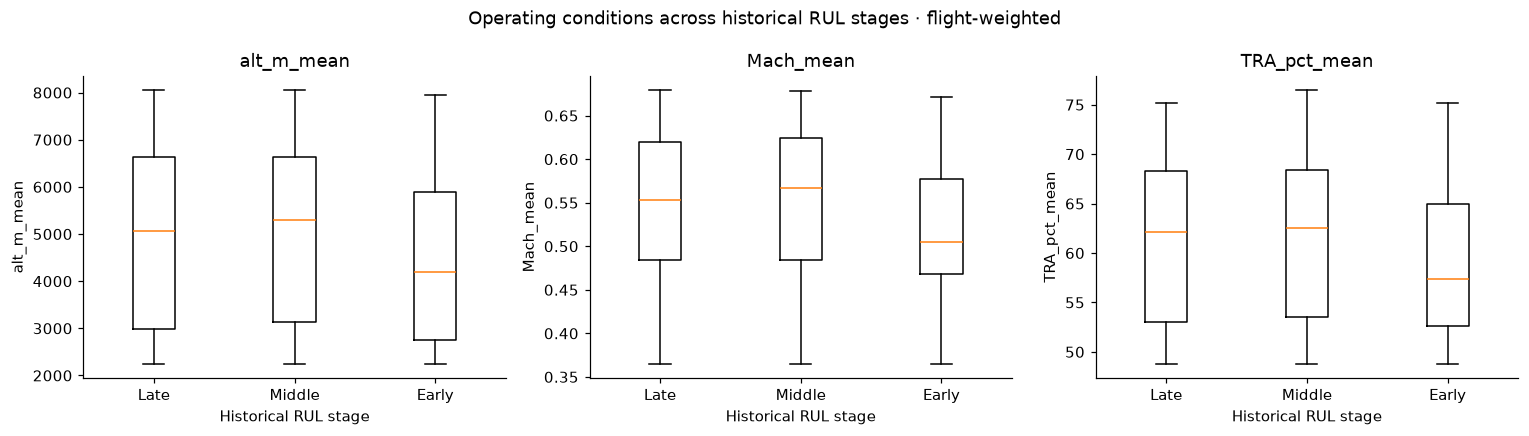

In [6]:
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,feature in zip(axes,conditions):
    vals=[train.loc[train.life_stage==s,feature].dropna() for s in ["Late","Middle","Early"]]
    ax.boxplot(vals,tick_labels=["Late","Middle","Early"],showfliers=False)
    ax.set(xlabel="Historical RUL stage",ylabel=feature,title=feature)
fig.suptitle("Operating conditions across historical RUL stages · flight-weighted")
fig.tight_layout()
fig.savefig(figdir/"05_operating_conditions.svg",bbox_inches="tight",metadata={"Date":None})
fig.savefig(figdir/"05_operating_conditions.png",bbox_inches="tight",dpi=180)
plt.show()

## 6. H2: historical changes
Compare the descriptive behavior of current-flight means and previous-flight differences (T48, Nc and Wf). Previous-flight differences are absent for a history's first flight; this is expected. No feature-importance or incremental prediction claim is possible without training/evaluation.

,count,mean,std,min,25%,50%,75%,max
T48_K_delta_prev,567.0,0.154176,12.800700,-45.267544,-8.465483,0.362617,7.821202,46.820224
Nc_rpm_delta_prev,567.0,-0.376776,54.232541,-209.008470,-31.676188,-0.066453,31.814973,193.681042
Wf_kg_s_delta_prev,567.0,0.000281,0.091192,-0.268506,-0.056724,0.000625,0.059648,0.305252


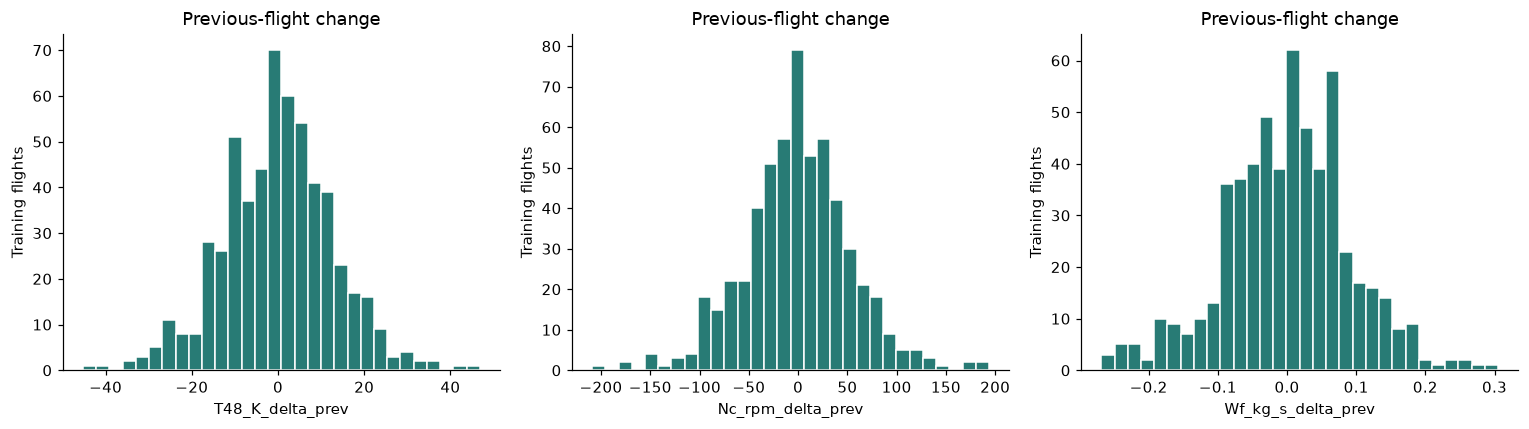

In [7]:
deltas=["T48_K_delta_prev","Nc_rpm_delta_prev","Wf_kg_s_delta_prev"]
delta_summary=train[deltas].describe().T
delta_summary.to_csv(outdir/"train_previous_flight_change_summary.csv")
display(delta_summary)
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,delta in zip(axes,deltas):
    v=train[delta].dropna()
    ax.hist(v,bins=30,color="#287b75",edgecolor="white")
    ax.set(xlabel=delta,ylabel="Training flights",title="Previous-flight change")
fig.tight_layout()
fig.savefig(figdir/"06_previous_flight_changes.svg",bbox_inches="tight",metadata={"Date":None})
fig.savefig(figdir/"06_previous_flight_changes.png",bbox_inches="tight",dpi=180)
plt.show()

## Training findings — before displaying validation
H1–H4 are exploratory questions. Results below are computed from training rows only.

In [8]:
info=training_insights(train)
(outdir/'training_insights.json').write_text(json.dumps(info,indent=2)+'\n')
display(Markdown(insight_markdown(info)))

### Training findings recorded before the validation output
- **H1 — sensor association:** T48–RUL Pearson r is negative in 7/7 training histories, ranging from -0.540 to -0.299. This is exploratory association, not proof of wear causality or validated prediction.
- **Retrospective grouping:** paired late-minus-early T48 engine medians are higher by a median 13.62 K across 7 histories (range 4.93–17.82 K). Groups use true RUL (0–20, 21–50, >50), so they cannot be deployed as known inputs.
- **H2 — historical changes:** each difference has 567 observed training values; the first flight in each history has no previous observation. Differences describe short-term changes; added predictive value is untested.
- **H3 — operating context:** altitude/Mach/throttle vary across flights and groups. Displayed medians document context; they do not establish a causal or adjusted effect. Whole-flight summaries mix phases.
- **H4 — heterogeneity:** Nc–RUL r ranges from -0.153 to 0.199, including both signs. T48 association also varies in magnitude. A universal sensor threshold is not justified.

**Business interpretation:** temperature context and recent history are candidates for later RUL modeling. Overestimating RUL could delay an intervention; underestimating could prompt premature maintenance. We have not demonstrated forecast accuracy, costs, savings, or operational suitability.

**Evidence scope:** 574 flights; 7 dataset-scoped histories but only 6 conservative unit-ID groups. No independent-observation significance tests. These data had already been examined during the integration review; this write-up is not a preregistered or blinded hypothesis test.

## 7. Fixed descriptive validation check
Training-only conclusions are recorded in the preceding cell. The existing branch chose T48, Nc and Wf; we keep that fixed set. These validation histories were already inspected during branch review, so this is not blinded replication. No test/quarantine sensor or target analysis is performed and no repeated hypothesis tuning is justified.

In [9]:
rows=[]
for eid,g in validation.groupby("engine_id"):
    for sensor in sensors:
        rows.append({"engine_id":eid,"sensor":sensor,"r_with_RUL":g[["RUL",sensor]].corr().iloc[0,1]})
validation_corr=pd.DataFrame(rows)
validation_corr.to_csv(outdir/"validation_per_engine_correlations.csv",index=False)
display(validation_corr.pivot(index="engine_id",columns="sensor",values="r_with_RUL"))

sensor,Nc_rpm_mean,T48_K_mean,Wf_kg_s_mean
engine_id,,,
DS01:5,0.158504,-0.470145,-0.152997
DS01:6,0.367927,-0.196018,-0.065183
DS02:18,0.155007,-0.325210,0.032483
DS02:5,0.126502,-0.421592,-0.150879


## 8. Key insights and business story
The training summary above records numerical findings and limitations. T48 is a candidate for later modeling; shaft speed and fuel-flow associations are engine-dependent. Context and history should be evaluated rather than assuming one universal threshold.

**What we can tell a maintenance planner:** our analysis identifies measurements worth investigating, not when to maintain a real engine. RUL overestimation could defer a needed intervention; underestimation could encourage premature work. No economic effects are measured.

**Next modeling stage:** compare a constant training-RUL baseline, linear regression, and random forest using grouped development validation. The mean constant minimizes squared error; a median constant is appropriate for absolute error. Report both MAE and RMSE, engine-wise errors and optimism. Test selection stays separate. No model has been trained here.

After executing all cells, run `python scripts/build_task5_report.py` to generate the report and dashboard. The short V6 presentation draft is generated separately by `python scripts/build_milestone_presentation.py`.

## Appendix — reproduce structural charts
These are Task 3 structural summaries, including historical test histories. They are not used for sensor hypothesis selection; healthy-cycle counts come from simulator health metadata, not a learned prediction.

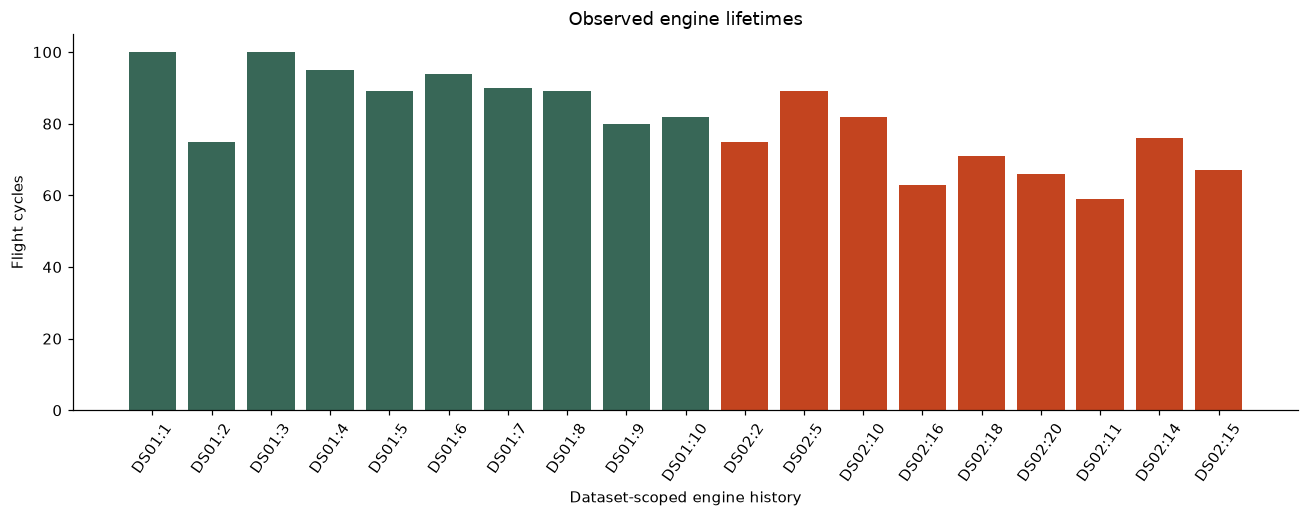

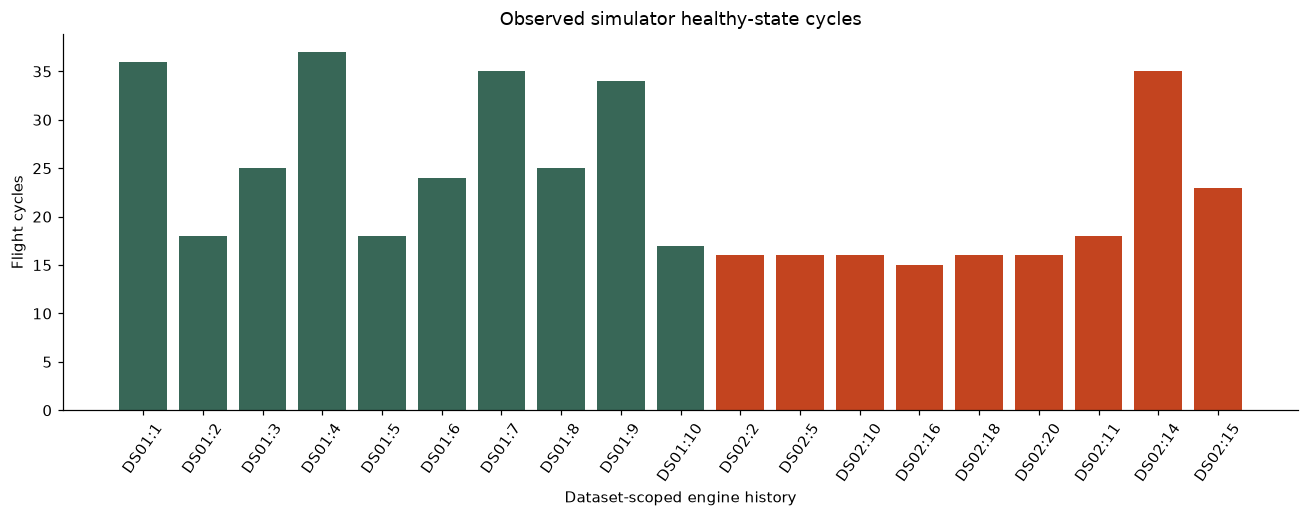

All outputs generated. Rebuild report/dashboard with python scripts/build_task5_report.py


In [10]:
engine_table=pd.read_csv(root/'reports/results/engines.csv')
for column,title,filename in [('cycles','Observed engine lifetimes','engine_lifetimes'),
                              ('healthy_cycles','Observed simulator healthy-state cycles','healthy_cycles')]:
    fig,ax=plt.subplots(figsize=(12,4.8))
    labels=engine_table.dataset+':'+engine_table.unit.astype(str)
    ax.bar(labels,engine_table[column],color=['#386757' if d=='DS01' else '#c3441f' for d in engine_table.dataset])
    ax.set(title=title,xlabel='Dataset-scoped engine history',ylabel='Flight cycles')
    ax.tick_params(axis='x',rotation=55)
    fig.tight_layout()
    fig.savefig(figdir/(filename+'.svg'),metadata={'Date':None})
    fig.savefig(figdir/(filename+'.png'),dpi=180)
    plt.show()
    plt.close(fig)
print('All outputs generated. Rebuild report/dashboard with python scripts/build_task5_report.py')